<a href="https://colab.research.google.com/github/YuncheKim/2026_sundaesu/blob/main/1031_%EC%84%A0%EB%8C%80%EC%88%98_%EC%A1%B0%EC%A2%85%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [2]:
def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

In [3]:
def draw_rectangle(ax, p1, p2, p3, p4, color='tab:blue', zorder=1):
    my_polygon = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor=color, zorder=zorder)
    ax.add_patch(my_polygon)


In [4]:
def transform(m, p):
  hp = np.array([p[0], p[1], 1.0])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [5]:
def translate(p, dx, dy):
    m = np.array([[1.0, 0.0, dx],
                  [0.0, 1.0, dy],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [6]:
def rotate(p, theta):
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                  [np.sin(theta),  np.cos(theta), 0.0],
                  [0.0,            0.0,           1.0]])
    return transform(m, p)

In [7]:
def scale(p, sx, sy):
    m = np.array([[sx,  0.0, 0.0],
                  [0.0, sy,  0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [8]:
def shear_x(p, sx):
    m = np.array([[1.0, sx,  0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [9]:
def shear_y(p, sy):
    m = np.array([[1.0, 0.0, 0.0],
                  [sy,  1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)


In [10]:
def reflect_x(p):
    m = np.array([[1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    return transform(m, p)

In [11]:
def reflect_y(p):
    m = np.array([[-1.0, 0.0, 0.0],
                  [ 0.0, 1.0, 0.0],
                  [ 0.0, 0.0, 1.0]])
    return transform(m, p)

In [12]:
def reflect_origin(p):
    m = np.array([[-1.0,  0.0, 0.0],
                  [ 0.0, -1.0, 0.0],
                  [ 0.0,  0.0, 1.0]])
    return transform(m, p)

In [13]:
def reflect_yx(p):
    m = np.array([[0.0, 1.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [14]:
WING_X = 800
WING_W = 60
WING_H = 450
ARM_T  = 50

In [15]:
def apply_all(points, f, *args):
    return [f(p, *args) for p in points]


In [34]:
def draw_cockpit(ax, p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 5, 5)
    q = apply_all(q, rotate, np.pi/4)
    draw_rectangle(ax, *q, color='tab:blue', zorder=4)

    w = [p1, p2, p3, p4]
    w = apply_all(w, translate, -LEN/2, -LEN/2)
    w = apply_all(w, scale, 2, 2)
    w = apply_all(w, rotate, np.pi/4)
    draw_rectangle(ax, *w, color='tab:blue', zorder=5)

In [17]:
def arm_points(p1, p2, p3, p4, a, b):
    d = np.array(b) - np.array(a)
    length = np.sqrt(d[0]**2 + d[1]**2)
    theta = np.arctan2(d[1], d[0])

    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, 0, -LEN/2)
    q = apply_all(q, scale, length/LEN, ARM_T/LEN)
    q = apply_all(q, rotate, theta)
    q = apply_all(q, translate, a[0], a[1])
    return q

In [18]:
def left_arm_points(p1, p2, p3, p4):
    upper = arm_points(p1, p2, p3, p4, (-WING_X, 15), (-120, 110))
    lower = [reflect_x(p) for p in upper]
    return upper, lower

In [33]:
def draw_left_arm(ax, p1, p2, p3, p4):
    for q in left_arm_points(p1, p2, p3, p4):
        draw_rectangle(ax, *q, color='tab:blue', zorder=2)



In [31]:
def draw_left_arm(ax, p1, p2, p3, p4):
    for q in left_arm_points(p1, p2, p3, p4):
        draw_rectangle(ax, *q, color='tab:blue', zorder=2)

In [20]:
def left_wing_points(p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, scale, WING_W/LEN, WING_H/LEN)
    q = apply_all(q, translate, -WING_W, 0)
    q = apply_all(q, shear_y, 2.0)
    q = apply_all(q, translate, -WING_X, 0)
    upper = q
    lower = [reflect_x(p) for p in upper]
    return upper, lower

In [26]:
def draw_left_wing(ax, p1, p2, p3, p4):
    for q in left_wing_points(p1, p2, p3, p4):
        draw_rectangle(ax, *q, color='tab:blue', zorder=3)

In [30]:
def draw_right_arm(ax, p1, p2, p3, p4):
    for q in left_arm_points(p1, p2, p3, p4):
        q = [reflect_y(p) for p in q]
        draw_rectangle(ax, *q, color='tab:blue', zorder=2)

In [21]:
def draw_right_wing(ax, p1, p2, p3, p4):
    for q in left_wing_points(p1, p2, p3, p4):
        q = [reflect_origin(p) for p in q]
        draw_rectangle(ax, *q, color='tab:blue', zorder=3)

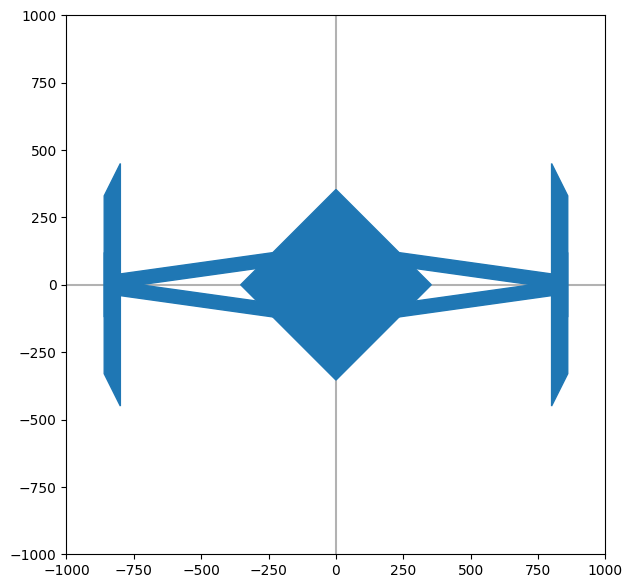

In [35]:
def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_cockpit(ax, p1, p2, p3, p4)
    draw_left_arm(ax, p1, p2, p3, p4)
    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)

fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()